# Task 4 — Pick the right chart, five times

This notebook uses the MPG dataset. The goal is to match each question to the most informative chart type and justify the choice.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

path = Path('data') / 'mpg.csv'
df = pd.read_csv(path)
df.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## 1) Did cars get more fuel-efficient between 1970 and 1982?
A line chart is appropriate because the question is about change over time.


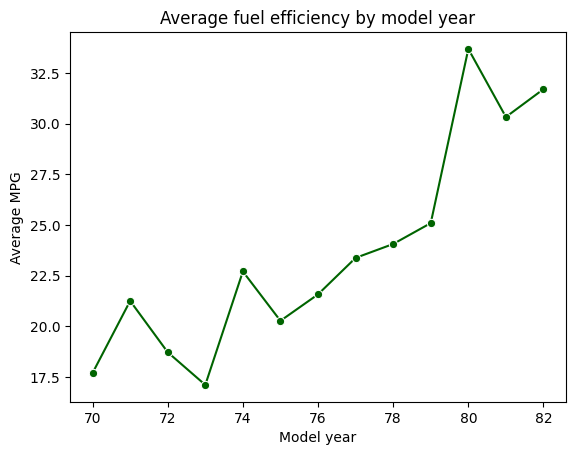

In [2]:
yearly_mpg = df.groupby('model_year', as_index=False)['mpg'].mean()

sns.lineplot(data=yearly_mpg, x='model_year', y='mpg', marker='o', color='darkgreen')
plt.title('Average fuel efficiency by model year')
plt.xlabel('Model year')
plt.ylabel('Average MPG')
plt.show()


### Justification
A line chart shows the trend over time clearly and makes the direction of change easy to read.


## 2) Do American, European and Japanese cars differ in fuel efficiency?
A boxplot compares distributions across groups and highlights spread as well as centre.


/var/folders/b7/n66x67qj3_57sghtm4d552j00000gn/T/ipykernel_90553/2964905207.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='origin', y='mpg', palette='Set2')


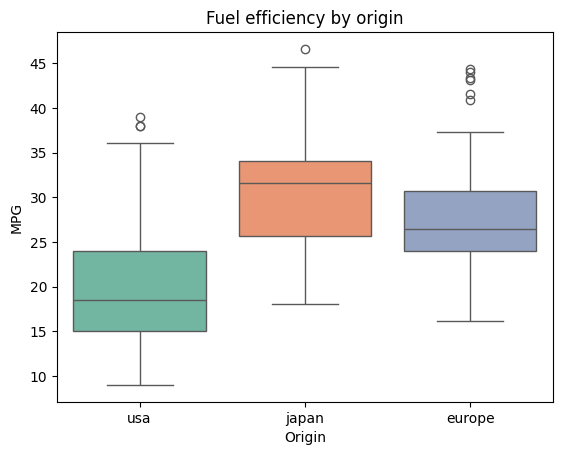

In [3]:
sns.boxplot(data=df, x='origin', y='mpg', palette='Set2')
plt.title('Fuel efficiency by origin')
plt.xlabel('Origin')
plt.ylabel('MPG')
plt.show()


### Justification
A boxplot is ideal because it summarizes the distribution of MPG for each region and shows both typical values and outliers.


## 3) What is the relationship between a car's weight and fuel efficiency?
A scatter plot is the correct choice because the question is about association between two continuous variables.


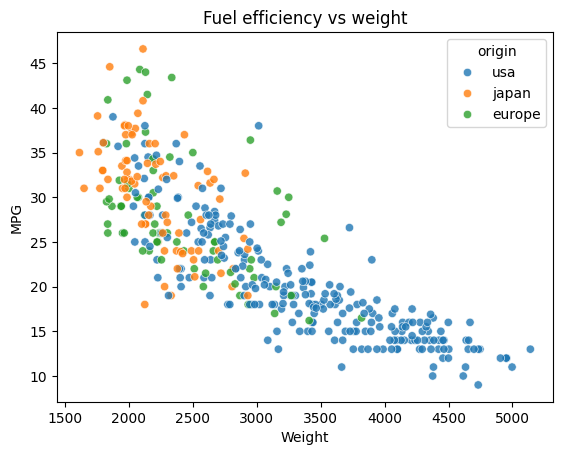

In [4]:
sns.scatterplot(data=df, x='weight', y='mpg', hue='origin', alpha=0.8)
plt.title('Fuel efficiency vs weight')
plt.xlabel('Weight')
plt.ylabel('MPG')
plt.show()


### Justification
A scatter plot shows the pattern between weight and MPG directly and lets us see whether the relationship is linear or shaped by different origins.


## 4) How is the number of cylinders distributed across the fleet?
A count plot (bar chart) is best for the distribution of a discrete variable.


/var/folders/b7/n66x67qj3_57sghtm4d552j00000gn/T/ipykernel_90553/3127474950.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='cylinders', palette='Blues_d')


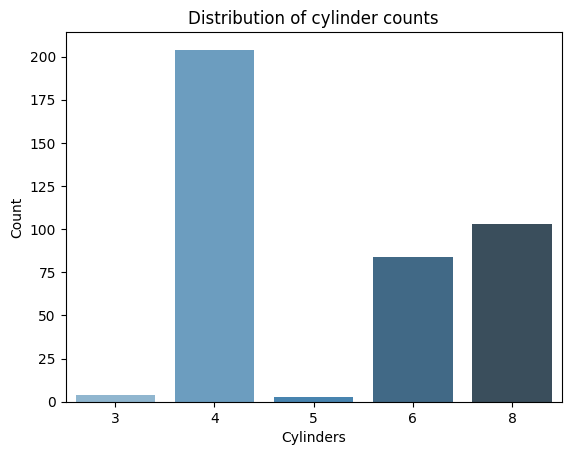

In [5]:
sns.countplot(data=df, x='cylinders', palette='Blues_d')
plt.title('Distribution of cylinder counts')
plt.xlabel('Cylinders')
plt.ylabel('Count')
plt.show()


### Justification
A count chart is the clearest way to show how often each cylinder count appears in the fleet.


## 5) Is the improvement in question 1 explained by question 3?
A line chart of average weight by year answers whether cars became lighter over time.


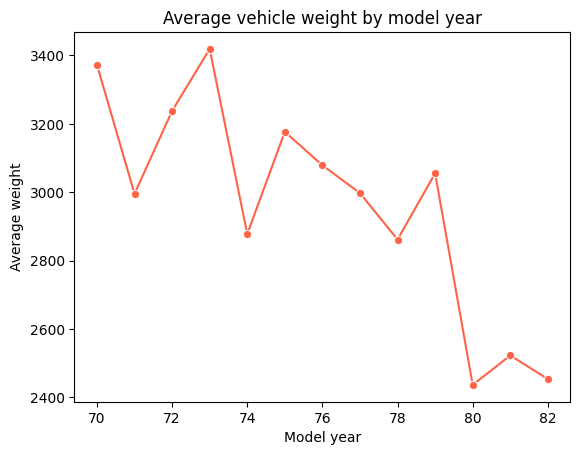

In [6]:
yearly_weight = df.groupby('model_year', as_index=False)['weight'].mean()

sns.lineplot(data=yearly_weight, x='model_year', y='weight', marker='o', color='tomato')
plt.title('Average vehicle weight by model year')
plt.xlabel('Model year')
plt.ylabel('Average weight')
plt.show()


### Justification
This line chart directly tests whether the fuel-efficiency gain corresponds to a systematic reduction in vehicle weight.


## Redraw the weakest chart
The weakest chart here is arguably the simple weight-by-year line on its own, because it has no direct comparison with MPG. A better version shows both average MPG and average weight on the same plot using a second axis only if carefully justified, but the cleaner option is to show them side by side or explain the relationship in a paired view.


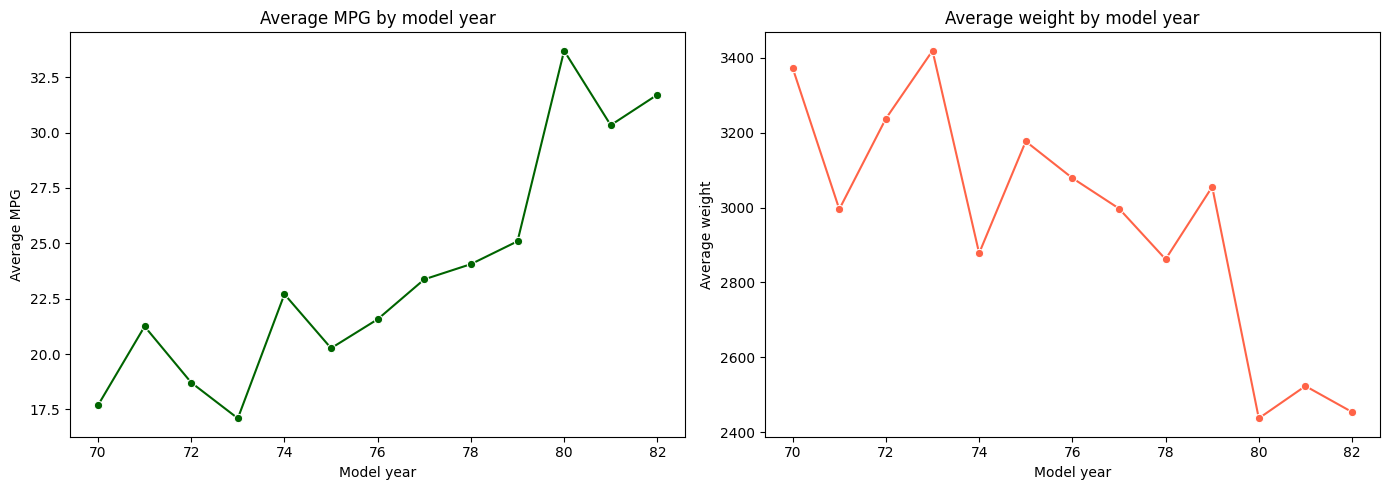

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=yearly_mpg, x='model_year', y='mpg', marker='o', ax=axes[0], color='darkgreen')
axes[0].set_title('Average MPG by model year')
axes[0].set_xlabel('Model year')
axes[0].set_ylabel('Average MPG')

sns.lineplot(data=yearly_weight, x='model_year', y='weight', marker='o', ax=axes[1], color='tomato')
axes[1].set_title('Average weight by model year')
axes[1].set_xlabel('Model year')
axes[1].set_ylabel('Average weight')

plt.tight_layout()
plt.show()
